# Análise de Dados de Compras da Hotmart e TMB 

### Objeto: Realizar uma análise descritiva da BF25 para as campanhas de vendas

In [2]:
# Importações básicas
import pandas as pd
import numpy as np
import sys
from pathlib import Path
import os
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), 'src'))

# Adiciona src ao path
sys.path.append('../src')

# Utilitários de dados
from data_utils import (
    load_raw_data,
    save_processed_data,
    remove_duplicates,
    handle_missing_values,
    detect_outliers,
    normalize_column,
    process_phone_string,
    process_phone_number,
    clean_and_lower_column,
    flatten_list_to_df,
    parse_utm_string
)

# Utilitários SQL
from sql_utils import DatabaseConnection as Dbc, load_query_from_file

# Utilitários de visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Utilitários de API
from api_utils import (
    make_request,
    get_json,
    post_json,
    paginated_request,
    response_to_dataframe
)

# utilitários hotmart
from hotmart_utils import Hotmart

# utilitários tmb
from tmb_utils import TMB   

# Configurações pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Load Database Driver
db = Dbc()

# Inicializar API Hotmart
hotmart = Hotmart()

# Inicializar API TMB
tmb = TMB()

print('✓ Importações concluídas com sucesso!')

✓ Importações concluídas com sucesso!


## Load Dataframes


In [3]:
df_ofan = db.execute_query_from_file('select_complete_lead_data_from_campaign', params={'conversion_type_id': '1', 'campaign_id': 'OFAN_25'})
df_ofan['phone'] = process_phone_string(df_ofan, 'phone')

print('df_ofan shape:', df_ofan.shape)

df_ofan_r = db.execute_query_from_file('select_complete_lead_data_from_campaign', params={'conversion_type_id': '1', 'campaign_id': 'OFAN_25R'})
df_ofan_r['phone'] = process_phone_string(df_ofan_r, 'phone')

print('df_ofan_r shape:', df_ofan_r.shape)

df_ofan_met = db.execute_query_from_file('select_complete_lead_data_from_campaign', params={'conversion_type_id': '1', 'campaign_id': 'OFAN_25RMET'})
df_ofan_met['phone'] = process_phone_string(df_ofan_met, 'phone')

print('df_ofan_met shape:', df_ofan_met.shape)

df_ofan shape: (23930, 13)
df_ofan_r shape: (12787, 13)
df_ofan_met shape: (1375, 13)


### tratamento das Compras Hotmart

In [2]:
df_hotmart = load_raw_data('hotmart.csv', sep=';')

In [3]:
df_hotmart = load_raw_data('hotmart.csv', sep=';')
df_hotmart_24 = load_raw_data('hotmart_24.csv', sep=';')

"""
Cell generated by Data Wrangler.
"""
def clean_data(df_hotmart):
    #df_hotmart = df_hotmart[(df_hotmart['Recorrência'] == 1) | (df_hotmart['Recorrência'].isna())]
    #df_hotmart = df_hotmart[(df_hotmart['Recorrência'] > 1)]
    df_hotmart['DDD'] = process_phone_string(df_hotmart, 'DDD')
    df_hotmart['Telefone'] = process_phone_string(df_hotmart, 'Telefone')
    df_hotmart['phone'] = df_hotmart.apply(lambda x: x['Telefone'] if pd.isna(x['DDD']) else f'55{x["DDD"]}{x["Telefone"]}', axis=1)
    # Drop column: 'DDD'
    df_hotmart = df_hotmart.drop(columns=['DDD', 'Telefone'])
    # Drop columns: 'Nome do Produtor', 'Documento do Produtor' and 39 other columns
    df_hotmart = df_hotmart.drop(columns=['Nome do Produtor', 'Documento do Produtor', 'Nome do Afiliado', 'Meio de Pagamento', 'Origem', 'Moeda', 'Preço do Produto', 'Moeda.1', 'Preço da Oferta', 'Taxa de Câmbio', 'Moeda.2', 'Preço Original', 'Número da Parcela', 'Status', 'Documento', 'CEP', 'Endereço', 'Número', 'Complemento', 'chave', 'Código do Produto', 'Código da Afiliação', 'Período Grátis', 'Tem co-produção', 'Venda feita como', 'Preço Total', 'Tipo pagamento oferta', 'Taxa de Câmbio Real', 'Preço Total Convertido', 'Quantidade de itens', 'Oferta de Upgrade', 'Cupom', 'Moeda.3', 'Data Vencimento', 'Instagram', 'Origem da venda', 'Moeda de recebimento', 'Código do assinante', 'Nota Fiscal', 'Valor do frete bruto'])
    # Rename column 'Código de Oferta' to 'offer_id'
    df_hotmart = df_hotmart.rename(columns={'Código de Oferta': 'offer_id'})
    # Rename column 'Nome do Produto' to 'product_name'
    df_hotmart = df_hotmart.rename(columns={'Nome do Produto': 'product_name'})
    # Rename column 'Transação' to 'transaction_code'
    df_hotmart = df_hotmart.rename(columns={'Transação': 'transaction_code'})
    # Rename column 'Data de Venda' to 'sale_date'
    df_hotmart = df_hotmart.rename(columns={'Data de Venda': 'sale_date'})
    # Rename column 'Data de Confirmação' to 'confirmation_name'
    df_hotmart = df_hotmart.rename(columns={'Data de Confirmação': 'confirmation_name'})
    # Rename column 'Nome' to 'name'
    df_hotmart = df_hotmart.rename(columns={'Nome': 'name'})
    # Rename column 'Email' to 'email'
    df_hotmart = df_hotmart.rename(columns={'Email': 'email'})
    # Rename column 'Cidade' to 'city'
    df_hotmart = df_hotmart.rename(columns={'Cidade': 'city'})
    # Rename column 'Estado' to 'state'
    df_hotmart = df_hotmart.rename(columns={'Estado': 'state'})
    # Rename column 'País' to 'contry'
    df_hotmart = df_hotmart.rename(columns={'País': 'contry'})
    # Rename column 'Bairro' to 'bairro'
    df_hotmart = df_hotmart.rename(columns={'Bairro': 'bairro'})
    # Rename column 'Origem de Checkout' to 'sck'
    df_hotmart = df_hotmart.rename(columns={'Origem de Checkout': 'sck'})
    # Rename column 'Tipo de Pagamento' to 'payment_method'
    df_hotmart = df_hotmart.rename(columns={'Tipo de Pagamento': 'payment_method'})
    # Rename column 'Valor que você recebeu convertido' to 'converted_value'
    df_hotmart = df_hotmart.rename(columns={'Valor que você recebeu convertido': 'converted_value'})
    # Rename column 'Taxa de Câmbio do valor recebido' to 'currency'
    df_hotmart = df_hotmart.rename(columns={'Taxa de Câmbio do valor recebido': 'currency'})
    # Rename column 'Faturamento líquido' to 'net_value'
    df_hotmart = df_hotmart.rename(columns={'Faturamento líquido': 'net_value'})
    
    df_hotmart['net_value'] = df_hotmart.apply(
        lambda x: x['net_value'] if pd.isna(x['currency']) else x['converted_value'],
        axis=1
    )
    # Drop columns: 'converted_value', 'currency'
    df_hotmart = df_hotmart.drop(columns=['converted_value', 'currency'])
    # Ajustando a conversão de datas considerando o formato 'dd/MM/yyyy HH:mm:ss'
    df_hotmart['sale_date'] = pd.to_datetime(df_hotmart['sale_date'], format="%d/%m/%Y %H:%M:%S", errors='coerce')
    df_hotmart['confirmation_name'] = pd.to_datetime(df_hotmart['confirmation_name'], format="%d/%m/%Y %H:%M:%S", errors='coerce')
    df_hotmart = parse_utm_string(df_hotmart, 'sck')
    return df_hotmart

df_hotmart = clean_data(df_hotmart.copy())
df_hotmart_24 = clean_data(df_hotmart_24.copy())
df_hotmart.head()

,product_name,transaction_code,Recorrência,sale_date,confirmation_name,name,email,city,state,bairro,contry,offer_id,sck,payment_method,net_value,phone,utm_source,utm_campaign,utm_content,utm_medium,utm_term,seller,campaign_id
0,Cronograma dos Fluentes,HP1934502206,NaN,2025-12-09 16:26:59,2025-12-09 16:27:03,Reginaldo Gomes da Silva,regynaldogs@gmail.com,Cascavel,PR,Centro,Brasil,c76jj7mb,utm_source=meta-ads&utm_medium=120238940530810...,Cartão de Crédito,1614.44,4407918688109,meta-ads,120238884915160140,120238940530890140,120238940530810140,120238940530810140,<NA>,lcto-bf25-alunos-fo
1,Cronograma dos Fluentes,HP2808636383,NaN,2025-12-09 16:21:30,2025-12-09 16:21:32,Rodrigo Araújo de Oliveira,rodrigopow@hotmail.com,São Paulo,SP,Vila Matilde,Brasil,rs1vpp7f,utm_source=sales&utm_campaign=sales&utm_conten...,Cartão de Crédito,1952.09,5511962224049,sales,sales,pvd,whatsapp,<NA>,julianamatos,<NA>
2,Cronograma dos Fluentes,HP2029519860,NaN,2025-12-09 16:08:44,2025-12-09 16:08:47,Rebeca Mendes Garcia,rebecamgarcia@hotmail.com,Campos Belos,GO,Aeroporto,Brasil,c0kpem44,utm_source=ig&utm_medium=social&utm_campaign=l...,Cartão de Crédito,2062.24,5563992221470,ig,lcto-bf25-leads-fo,link_in_bio,social,<NA>,<NA>,lcto-bf25-leads-fo
3,Cronograma dos Fluentes,HP2189575403,NaN,2025-12-09 16:04:47,2025-12-09 16:04:49,Elma Gomes Diniz Bombardieri,elmagdiniz@gmail.com,Curitiba,PR,Parolin,Brasil,3pq6l619,utm_source=sales&utm_campaign=sales&utm_conten...,Cartão de Crédito,1900.00,5541991853966,sales,sales,pvd,whatsapp,<NA>,isabelleguimaraes,<NA>
4,Cronograma dos Fluentes,HP2530078179,9.0,2025-12-09 15:57:41,2025-12-09 16:02:50,guilherme santos porto,guilherme.santos1139@gmail.com,São Sebastião de Lagoa de Roça,PB,centro,Brasil,owx4t3q0,us:sales|uc:sales|uo:pvd|um:whatsapp|s:sandra,Pix,179.74,5583998081773,sales,sales,pvd,whatsapp,<NA>,sandra,<NA>


### Tratar dados de Oferta

In [4]:
df_offers = db.execute_query_from_file('select_all_offers')

"""
Cell generated by Data Wrangler.
"""
def clean_data(df_offers):
    # Drop columns: 'updated_at', 'created_at' and 13 other columns
    df_offers = df_offers.drop(columns=['updated_at', 'created_at', 'status', 'description', 'start_date', 'end_date', 'price', 'main_product_id', 'access_duration_months', 'is_default', 'entry_value', 'installment_12x_value', 'is_child', 'comercial_use'])
    # Filter rows based on column: 'campaign_id'
    df_offers = df_offers[df_offers['campaign_id'].str.contains("lcto-bf25", regex=False, na=False, case=False)]
    return df_offers

df_offers = clean_data(df_offers.copy())
df_offers.head()

,offer_id,name,campaign_id,platform,base_url
7,aflr0gju,[BF25] Oferta Live - v2,lcto-bf25-leads,Hotmart,https://pay.hotmart.com/M86482747L?off=aflr0gju
8,i2jmb51w,[CS][BF25A] Oferta Pós-Live 2,lcto-bf25-alunos,Hotmart,https://pay.hotmart.com/M86482747L?off=i2jmb51w
9,mvwlubmu,[CS][BF25-Alunos] Acompanhamento Individual\t,lcto-bf25-leads,Hotmart,https://pay.hotmart.com/A102396443R?off=s1w43d...
10,c0kpem44,[BF25-FO] Oferta Live,lcto-bf25-leads-fo,Hotmart,https://pay.hotmart.com/M86482747L?off=c0kpem4...
11,5y0p2gzz,[COM][BF25A] Oferta 2 - 2 anos de acesso - Dow...,lcto-bf25-alunos,Hotmart,https://pay.hotmart.com/M86482747L?off=5y0p2gzz


# Realizando Merge no Dataframes


In [5]:
df_hot_offers = pd.merge(df_hotmart, df_offers, on='offer_id', how='left')

# Plotatando Visualizações

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from math import floor

# Load dataset
df = df_hot_offers
df['sale_date'] = pd.to_datetime(df['sale_date'])
df['sale_date_only'] = df['sale_date'].dt.date

# Prepare daily MC
mc_diaria = (
    df.groupby('sale_date_only', as_index=False)
      .agg(receita=('net_value', 'sum'))
      .rename(columns={'sale_date_only': 'sale_date'})
)
mc_diaria['mc_acumulada'] = mc_diaria['receita'].cumsum() * 0.6

# Dates
data_inicio = pd.to_datetime(mc_diaria['sale_date'].min())
data_fim = pd.to_datetime("2025-12-20")

# Filtra a série até o dia 20/12/2025
mc_diaria = mc_diaria[mc_diaria['sale_date'] <= data_fim]

x_dates = pd.to_datetime(mc_diaria['sale_date'])
y_vals = mc_diaria['mc_acumulada']

# Targets (metas)
mc_targets = [
    {"atingimento": "80%", "mc": 1726930},
    {"atingimento": "100%", "mc": 2262662},
    {"atingimento": "120%", "mc": 2788395},
    {"atingimento": "150%", "mc": 3596993},
    {"atingimento": "180%", "mc": 4395592},
    {"atingimento": "220%", "mc": 5467057},
    {"atingimento": "10M", "mc": 6246947},
]

# Gold gradient
gold_palette = [
    "#E8D7A1", "#E0C77F", "#D9B760",
    "#D1A741", "#C9961D", "#BF8A0A",
    "#B57E00"
]

# Descobre a meta mais próxima acima do acumulado atual
ultimo_y = y_vals.iloc[-1] if len(y_vals) > 0 else 0
meta_mais_proxima = None
for t in mc_targets:
    if ultimo_y < t["mc"]:
        meta_mais_proxima = t
        break
if meta_mais_proxima is None and len(mc_targets) > 0:
    # Acumulado já atingiu todas as metas
    meta_mais_proxima = mc_targets[-1]

gap_para_meta = meta_mais_proxima["mc"] - ultimo_y if meta_mais_proxima else 0

# ---------------- PLOT ----------------
plt.figure(figsize=(18, 9))
ax = plt.gca()
plt.rcParams["font.family"] = "DejaVu Sans"

# Plot metas
for i, t in enumerate(mc_targets):
    plt.hlines(
        y=t["mc"],
        xmin=data_inicio,
        xmax=data_fim,
        color=gold_palette[i],
        linewidth=2.2,
        alpha=0.55,
    )
    # right-side label
    plt.text(
        data_fim + pd.Timedelta(days=1),
        t["mc"],
        f"Meta {t['atingimento']} (R$ {t['mc']:,})",
        va='center',
        fontsize=11,
        color=gold_palette[i]
    )

# Plot MC acumulada
plt.plot(
    x_dates,
    y_vals,
    marker='o',
    markersize=6,
    markerfacecolor="#002540",
    markeredgecolor="#002540",
    linewidth=3,
    color="#002540",
    label="MC acumulada (60%)"
)

# Labels for MC
last_y = -np.inf
min_gap = (max(y_vals) - min(y_vals)) * 0.04 if len(y_vals) > 1 else 0

# Guarantee last point is always labeled
labeled_last = False
for idx, (x, y) in enumerate(zip(x_dates, y_vals)):
    is_last = (idx == len(x_dates)-1)
    # Label if the gap is enough, or if it's the last point (even if it was just labeled)
    should_label = (abs(y - last_y) > min_gap) or is_last
    if should_label:
        plt.annotate(
            f"{floor(y):,}".replace(",", "."),
            xy=(x, y),
            xytext=(0, 10),
            textcoords="offset points",
            fontsize=11,
            ha='center',
            bbox=dict(
                boxstyle="round,pad=0.3",
                fc="#FFFFFF",
                ec="#E2E2E2",
                lw=0.7,
                alpha=0.95
            )
        )
        last_y = y
        if is_last:
            labeled_last = True

# Extra label if loop skipped last
if not labeled_last and len(x_dates) > 0:
    x = x_dates.iloc[-1]
    y = y_vals.iloc[-1]
    plt.annotate(
        f"{floor(y):,}".replace(",", "."),
        xy=(x, y),
        xytext=(0, 10),
        textcoords="offset points",
        fontsize=11,
        ha='center',
        bbox=dict(
            boxstyle="round,pad=0.3",
            fc="#FFFFFF",
            ec="#E2E2E2",
            lw=0.7,
            alpha=0.95
        )
    )

# Adiciona anotação com gap para meta mais próxima perto do último ponto
if meta_mais_proxima is not None and len(x_dates) > 0:
    x = x_dates.iloc[-1]
    y = y_vals.iloc[-1]
    plt.annotate(
        f"Faltam R$ {int(gap_para_meta):,} para meta {meta_mais_proxima['atingimento']}".replace(",", "."),
        xy=(x, y),
        xytext=(20, 0),
        textcoords="offset points",
        fontsize=13,
        color=gold_palette[mc_targets.index(meta_mais_proxima)],
        fontweight='bold',
        bbox=dict(
            boxstyle="round,pad=0.4",
            fc="#FFFBE6",
            ec=gold_palette[mc_targets.index(meta_mais_proxima)],
            lw=1.2,
            alpha=0.97
        ),
        va='center', ha='left'
    )

# Formatting
plt.xticks(rotation=45, fontsize=11)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):,}".replace(",", ".")))
plt.xlabel("Data", fontsize=14)
plt.ylabel("R$", fontsize=14)
plt.title("Margem de Contribuição (60%) — Evolução diária", fontsize=18, pad=20)

plt.grid(color="#DDDDDD", linestyle='-', linewidth=0.5, alpha=0.5)
plt.tight_layout()
plt.show()


TypeError: Cannot compare Timestamp with datetime.date. Use ts == pd.Timestamp(date) or ts.date() == date instead.

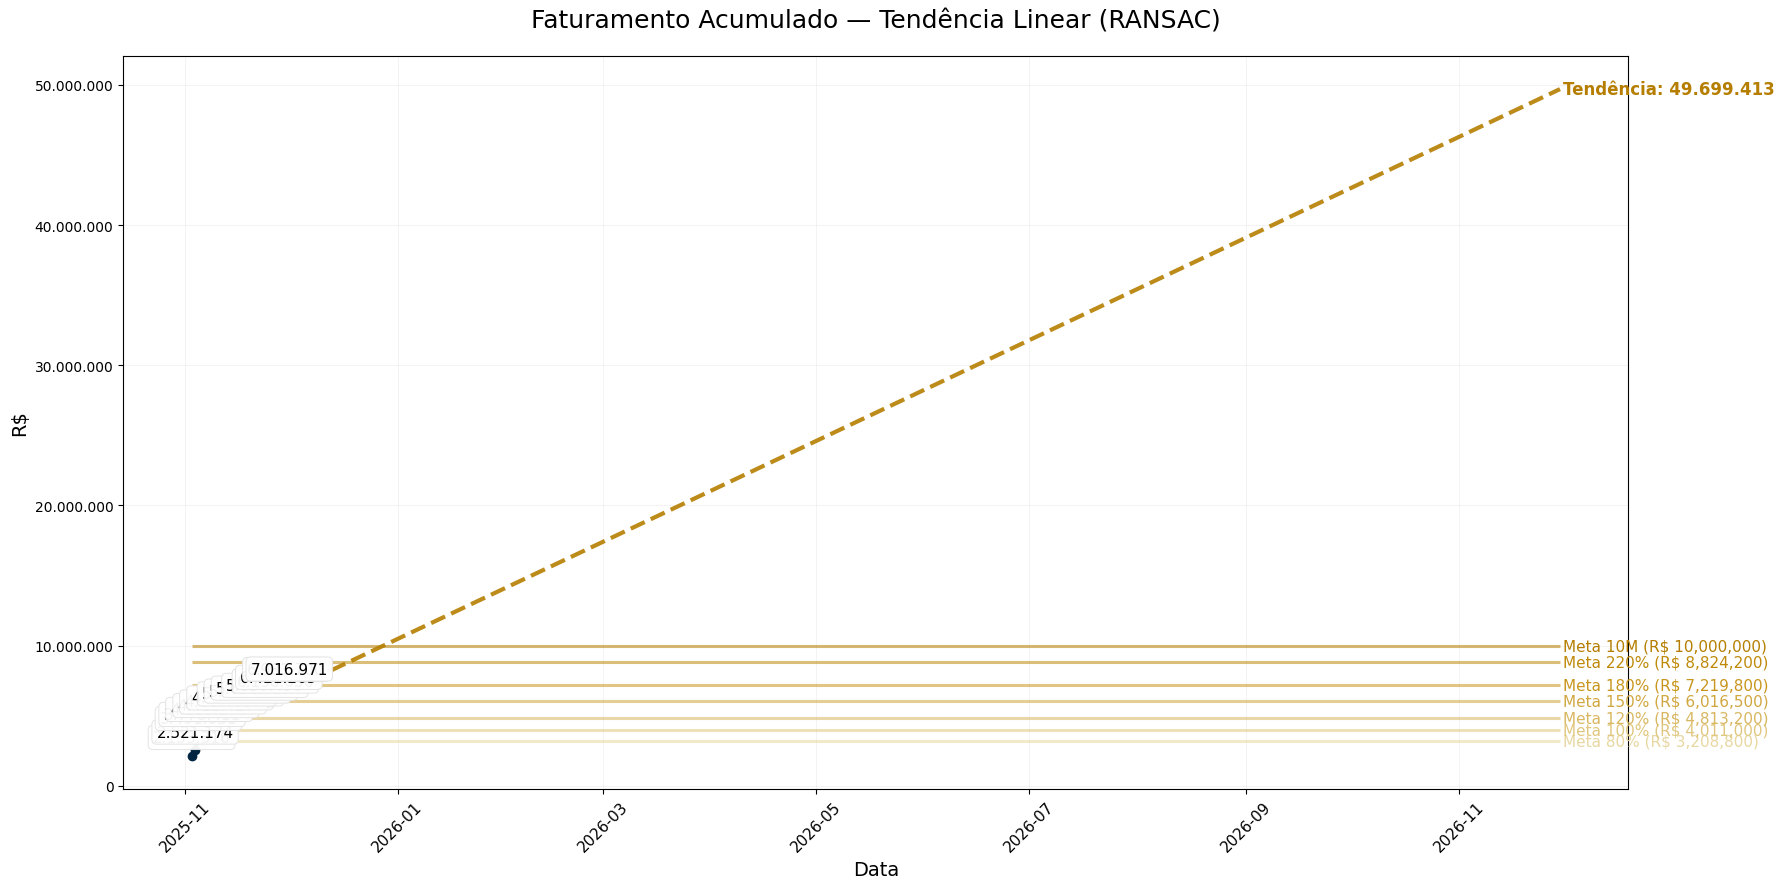

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from math import floor
from sklearn.linear_model import RANSACRegressor, LinearRegression

# Carregar dataset
df = df_hot_offers
df['sale_date'] = pd.to_datetime(df['sale_date'])
df['sale_date_only'] = df['sale_date'].dt.date

# Receita diária acumulada (Faturamento Acumulado)
faturamento_diario = (
    df.groupby('sale_date_only', as_index=False)
      .agg(receita=('net_value', 'sum'))
      .rename(columns={'sale_date_only': 'sale_date'})
)
faturamento_diario['faturamento_acumulado'] = faturamento_diario['receita'].cumsum()

# Datas
data_inicio = pd.to_datetime(faturamento_diario['sale_date'].min())
data_fim = pd.to_datetime(f"{data_inicio.year}-11-30")
if data_fim < pd.to_datetime(faturamento_diario['sale_date'].max()):
    data_fim = pd.to_datetime(f"{data_inicio.year+1}-11-30")

x_dates = pd.to_datetime(faturamento_diario['sale_date'])
y_vals = faturamento_diario['faturamento_acumulado']
X_num = (x_dates - data_inicio).dt.days.values.reshape(-1, 1)

# Projeção futura
future_dates = pd.date_range(start=x_dates.min(), end=data_fim, freq="D")
future_X = (future_dates - data_inicio).days.values.reshape(-1, 1)

# Tendência RANSAC
ransac = RANSACRegressor(LinearRegression())
ransac.fit(X_num, y_vals)
pred_ransac = ransac.predict(future_X)

# Metas (exemplo, ajuste conforme necessário)
faturamento_targets = [
    {"atingimento": "80%", "faturamento": 3208800},   # 1726930 / 0.6
    {"atingimento": "100%", "faturamento": 4011000},  # 2262662 / 0.6
    {"atingimento": "120%", "faturamento": 4813200},  # 2788395 / 0.6
    {"atingimento": "150%", "faturamento": 6016500},  # 3596993 / 0.6
    {"atingimento": "180%", "faturamento": 7219800},  # 4395592 / 0.6
    {"atingimento": "220%", "faturamento": 8824200},  # 5467057 / 0.6
    {"atingimento": "10M", "faturamento": 10000000},  # 6246947 / 0.6
]

# Paleta dourada
gold_palette = [
    "#E8D7A1", "#E0C77F", "#D9B760",
    "#D1A741", "#C9961D", "#BF8A0A",
    "#B57E00"
]

# ---------------- PLOT (Final Clean Version) ----------------
plt.figure(figsize=(18, 9))
ax = plt.gca()
plt.rcParams["font.family"] = "DejaVu Sans"

# Plot metas
for i, t in enumerate(faturamento_targets):
    plt.hlines(
        y=t["faturamento"],
        xmin=data_inicio,
        xmax=data_fim,
        color=gold_palette[i],
        linewidth=2.2,
        alpha=0.55,
    )
    # label à direita
    plt.text(
        data_fim + pd.Timedelta(days=1),
        t["faturamento"],
        f"Meta {t['atingimento']} (R$ {t['faturamento']:,})",
        va='center',
        fontsize=11,
        color=gold_palette[i]
    )

# Plot faturamento acumulado
plt.plot(
    x_dates,
    y_vals,
    marker='o',
    markersize=6,
    markerfacecolor="#002540",
    markeredgecolor="#002540",
    linewidth=3,
    color="#002540",
    label="Faturamento acumulado"
)

# Labels para Faturamento Acumulado
last_y = -np.inf
min_gap = (max(y_vals) - min(y_vals)) * 0.04

labeled_last = False
for idx, (x, y) in enumerate(zip(x_dates, y_vals)):
    is_last = (idx == len(x_dates)-1)
    should_label = (abs(y - last_y) > min_gap) or is_last
    if should_label:
        plt.annotate(
            f"{floor(y):,}".replace(",", "."),
            xy=(x, y),
            xytext=(0, 10),
            textcoords="offset points",
            fontsize=11,
            ha='center',
            bbox=dict(
                boxstyle="round,pad=0.3",
                fc="#FFFFFF",
                ec="#E2E2E2",
                lw=0.7,
                alpha=0.95
            )
        )
        last_y = y
        if is_last:
            labeled_last = True

# Caso a última label não tenha sido plotada (caso extremo)
if not labeled_last and len(x_dates) > 0:
    x = x_dates.iloc[-1]
    y = y_vals.iloc[-1]
    plt.annotate(
        f"{floor(y):,}".replace(",", "."),
        xy=(x, y),
        xytext=(0, 10),
        textcoords="offset points",
        fontsize=11,
        ha='center',
        bbox=dict(
            boxstyle="round,pad=0.3",
            fc="#FFFFFF",
            ec="#E2E2E2",
            lw=0.7,
            alpha=0.95
        )
    )

# Plot da reta de tendência RANSAC
plt.plot(
    future_dates,
    pred_ransac,
    linestyle='--',
    color="#B57E00",
    linewidth=3,
    alpha=0.9,
    label="Tendência Linear (RANSAC)"
)

# Trend label à direita
plt.text(
    data_fim + pd.Timedelta(days=1),
    pred_ransac[-1],
    f"Tendência: {int(pred_ransac[-1]):,}".replace(",", "."),
    va='center',
    fontsize=12,
    color="#B57E00",
    fontweight='bold'
)

# Formatação
plt.xticks(rotation=45, fontsize=11)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):,}".replace(",", ".")))
plt.xlabel("Data", fontsize=14)
plt.ylabel("R$", fontsize=14)
plt.title("Faturamento Acumulado — Tendência Linear (RANSAC)", fontsize=18, pad=20)

plt.grid(color="#DDDDDD", linestyle='-', linewidth=0.5, alpha=0.5)
plt.tight_layout()
plt.show()


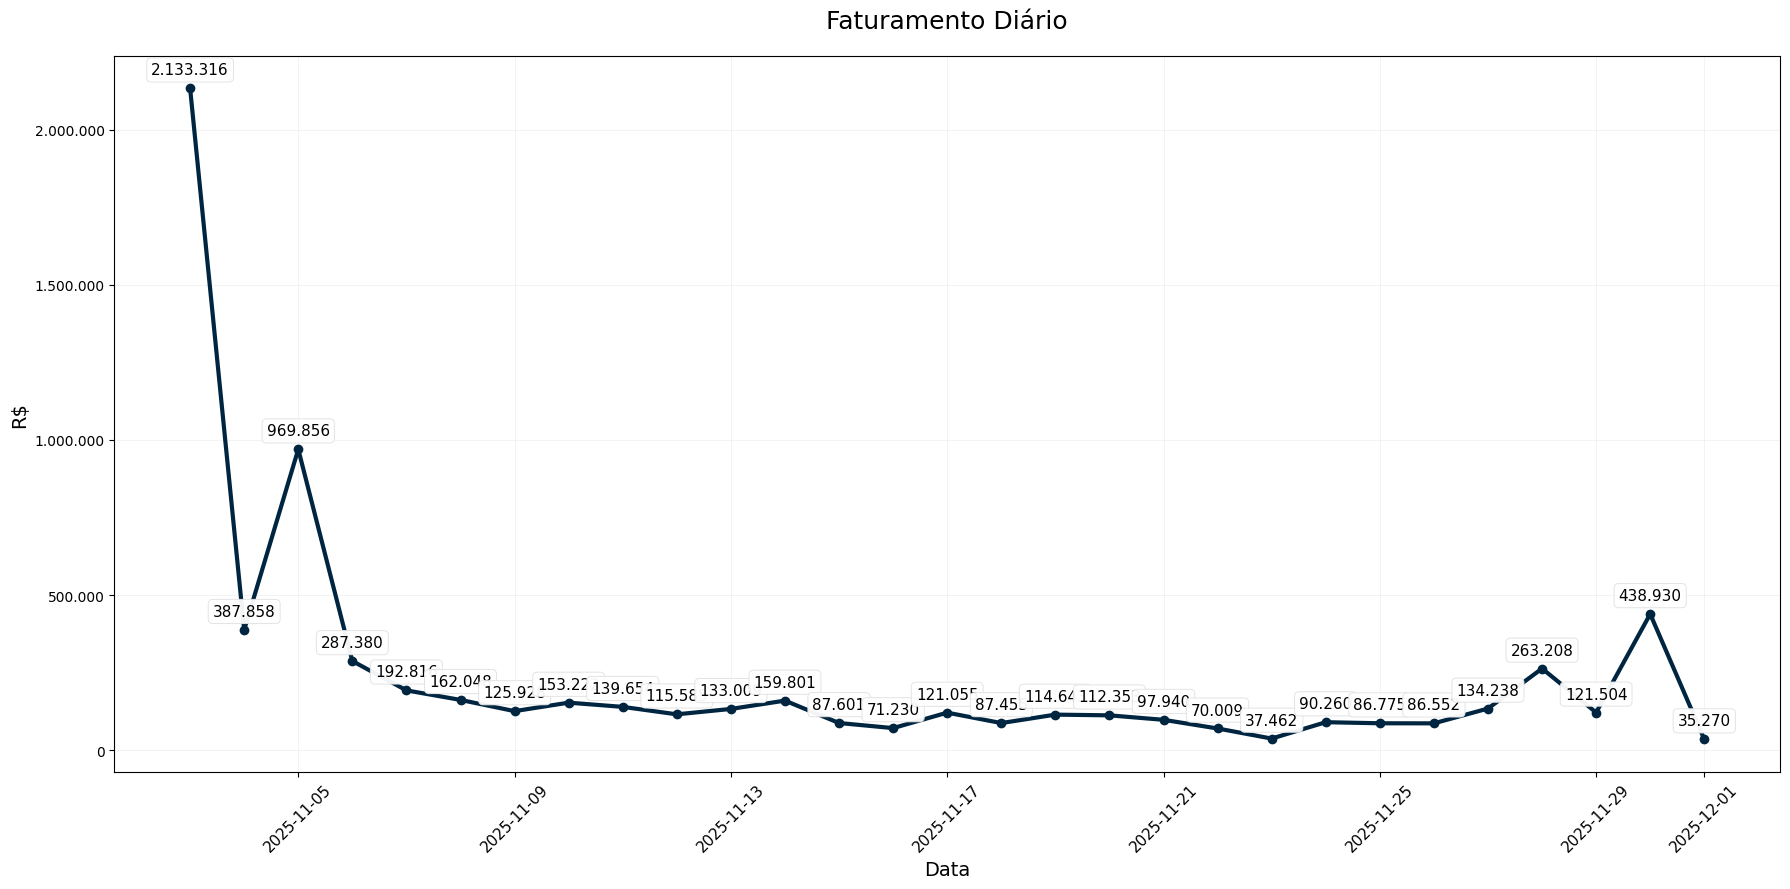

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from math import floor

# Carregar dados
df = df_hot_offers
df['sale_date'] = pd.to_datetime(df['sale_date'])
df['sale_date_only'] = df['sale_date'].dt.date

# Faturamento diário (não acumulado)
faturamento_diario = (
    df.groupby('sale_date_only', as_index=False)
      .agg(receita=('net_value', 'sum'))
      .rename(columns={'sale_date_only': 'sale_date'})
)

data_inicio = pd.to_datetime(faturamento_diario['sale_date'].min())
data_fim = pd.to_datetime(f"{data_inicio.year}-11-30")
if data_fim < pd.to_datetime(faturamento_diario['sale_date'].max()):
    data_fim = pd.to_datetime(f"{data_inicio.year+1}-11-30")

x_dates = pd.to_datetime(faturamento_diario['sale_date'])
y_vals = faturamento_diario['receita']

# ---------------- PLOT ----------------
plt.figure(figsize=(18, 9))
ax = plt.gca()
plt.rcParams["font.family"] = "DejaVu Sans"

# Plot faturamento diário
plt.plot(
    x_dates,
    y_vals,
    marker='o',
    markersize=6,
    markerfacecolor="#002540",
    markeredgecolor="#002540",
    linewidth=3,
    color="#002540",
    label="Faturamento do dia"
)

# Rótulos em todos os pontos
for x, y in zip(x_dates, y_vals):
    plt.annotate(
        f"{floor(y):,}".replace(",", "."),
        xy=(x, y),
        xytext=(0, 10),
        textcoords="offset points",
        fontsize=11,
        ha='center',
        bbox=dict(
            boxstyle="round,pad=0.3",
            fc="#FFFFFF",
            ec="#E2E2E2",
            lw=0.7,
            alpha=0.95
        )
    )

# Formatação
plt.xticks(rotation=45, fontsize=11)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):,}".replace(",", ".")))
plt.xlabel("Data", fontsize=14)
plt.ylabel("R$", fontsize=14)
plt.title("Faturamento Diário", fontsize=18, pad=20)
plt.grid(color="#DDDDDD", linestyle='-', linewidth=0.5, alpha=0.5)
plt.tight_layout()
plt.show()

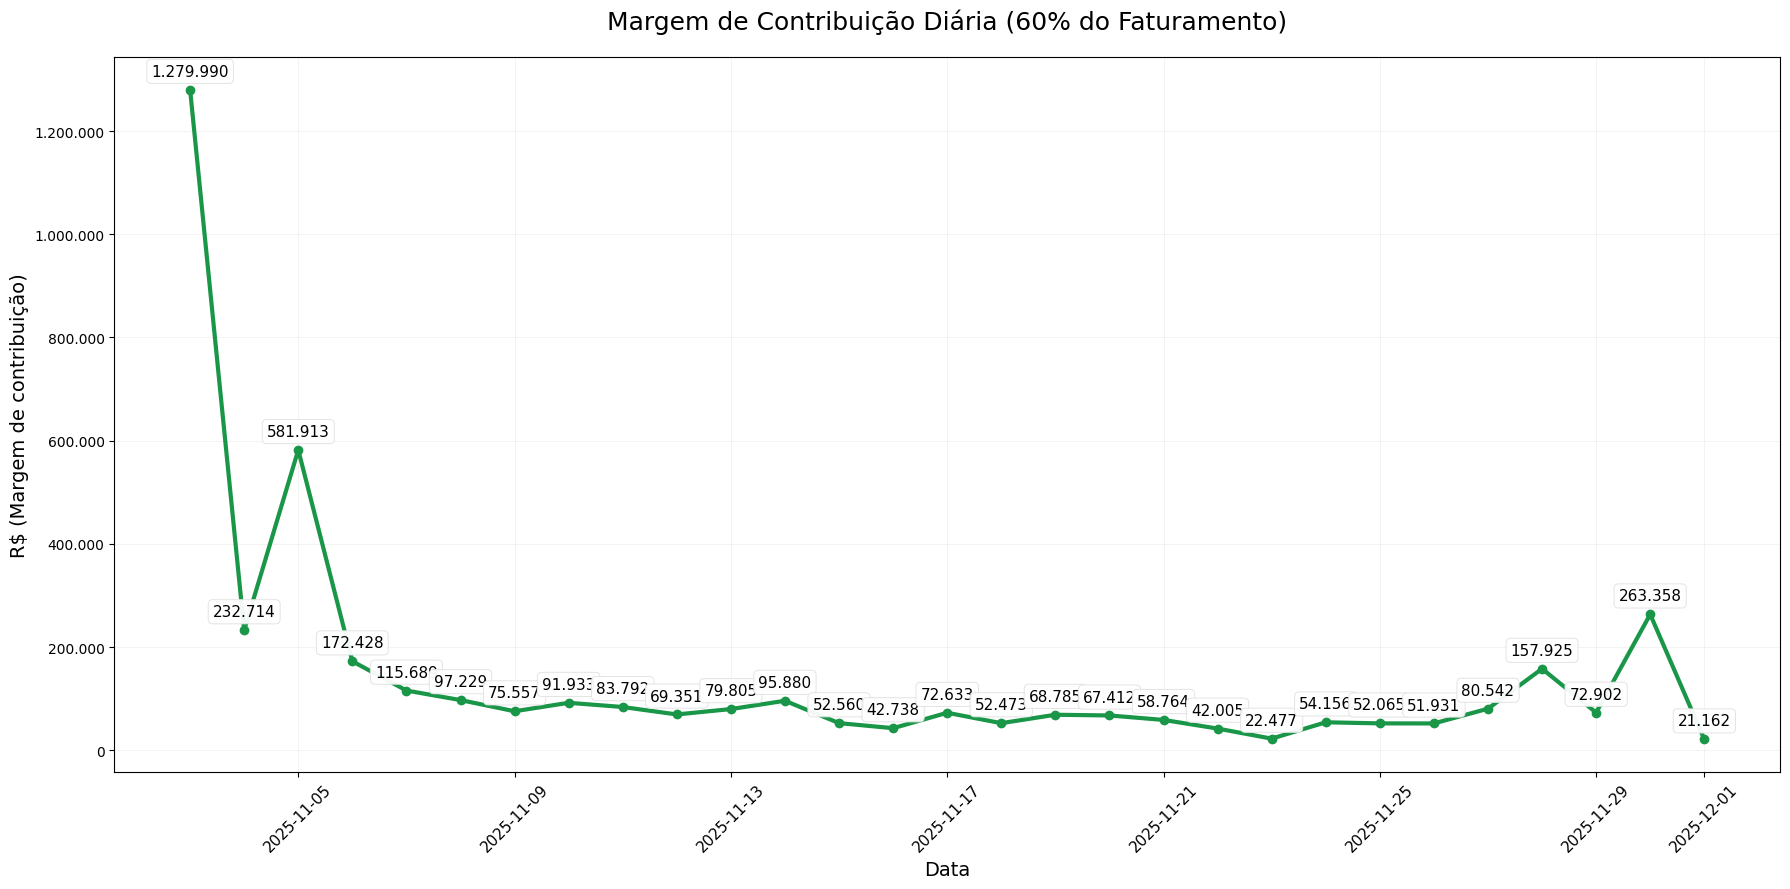

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from math import floor

# Carregar dados
df = df_hot_offers
df['sale_date'] = pd.to_datetime(df['sale_date'])
df['sale_date_only'] = df['sale_date'].dt.date

# Faturamento diário (não acumulado)
faturamento_diario = (
    df.groupby('sale_date_only', as_index=False)
      .agg(receita=('net_value', 'sum'))
      .rename(columns={'sale_date_only': 'sale_date'})
)

# Calcular a margem de contribuição diária (60% do faturamento diário)
faturamento_diario['margem_contribuicao'] = faturamento_diario['receita'] * 0.6

x_dates = pd.to_datetime(faturamento_diario['sale_date'])
y_vals = faturamento_diario['margem_contribuicao']

# ---------------- PLOT ----------------
plt.figure(figsize=(18, 9))
ax = plt.gca()
plt.rcParams["font.family"] = "DejaVu Sans"

# Plot margem de contribuição diária
plt.plot(
    x_dates,
    y_vals,
    marker='o',
    markersize=6,
    markerfacecolor="#199647",
    markeredgecolor="#199647",
    linewidth=3,
    color="#199647",
    label="Margem de contribuição do dia (60%)"
)

# Rótulos em todos os pontos
for x, y in zip(x_dates, y_vals):
    plt.annotate(
        f"{floor(y):,}".replace(",", "."),
        xy=(x, y),
        xytext=(0, 10),
        textcoords="offset points",
        fontsize=11,
        ha='center',
        bbox=dict(
            boxstyle="round,pad=0.3",
            fc="#FFFFFF",
            ec="#E2E2E2",
            lw=0.7,
            alpha=0.95
        )
    )

# Formatação
plt.xticks(rotation=45, fontsize=11)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):,}".replace(",", ".")))
plt.xlabel("Data", fontsize=14)
plt.ylabel("R$ (Margem de contribuição)", fontsize=14)
plt.title("Margem de Contribuição Diária (60% do Faturamento)", fontsize=18, pad=20)
plt.grid(color="#DDDDDD", linestyle='-', linewidth=0.5, alpha=0.5)
plt.tight_layout()
plt.show()
